# Group Project 2: 2D Particle Filter 

*EN.605.613 Introduction to Robotics*

Team Members: Shivam Pandey, Anna McCulloh, Hyeyun Jeong

This notebook extends the 1D particle filter example to estimate a robot position in x and y using a distance map, Gaussian motion noise, sensor likelihoods, and resampling.

In [31]:
import numpy as np
import matplotlib.pyplot as plt

In [32]:
%pip install numpy matplotlib


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Distance Map
Create the distance map used to compare sensor readings with possible robot positions.

In [33]:
def get_neighbors(cell: tuple[int, int], map: np.ndarray) -> list(tuple[int, int]):
    """ Gets a numpy array with all the adjacent cell indices """
    cell_idx = np.array(cell)
    neighbors = cell_idx[None,:]+np.array([[-1,0],[1,0],[0,-1],[0,1]])
    not_edge_of_map = (neighbors[:,0]>=0) & (neighbors[:,0]<map.shape[0]) & (neighbors[:,1]>=0) & (neighbors[:,1]<map.shape[1])
    neighbors = [tuple(n) for n in neighbors[not_edge_of_map]]
    return neighbors

[[6. 5. 4. 3. 3. 4. 5. 6. 7. 8.]
 [5. 4. 3. 2. 2. 3. 4. 5. 6. 7.]
 [4. 3. 2. 1. 1. 2. 3. 4. 5. 6.]
 [3. 2. 1. 0. 0. 1. 2. 3. 4. 5.]
 [3. 2. 1. 0. 1. 2. 3. 4. 4. 5.]
 [4. 3. 2. 1. 2. 3. 4. 4. 3. 4.]
 [5. 4. 3. 2. 3. 4. 4. 3. 2. 3.]
 [6. 5. 4. 3. 4. 4. 3. 2. 1. 2.]
 [7. 6. 5. 4. 4. 3. 2. 1. 0. 1.]
 [8. 7. 6. 5. 5. 4. 3. 2. 1. 2.]]


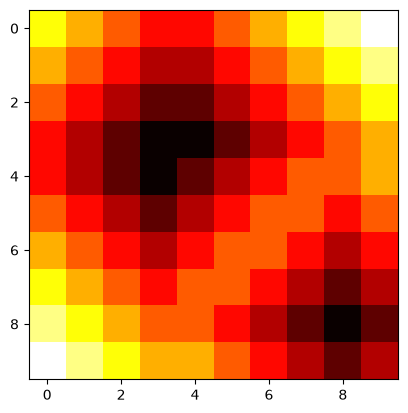

In [34]:
def lower_cells(map: np.ndarray, cells: list[tuple[int, int]], distance):
    """
    Updates cells with an decreasing distance from an obstacle.
    Used to insert an obstacle and update its neighbors.
    """
    # Initialize the original cells to the specified distance
    for cell in cells:
      map[cell[0], cell[1]] = distance

    open_list = cells.copy()
    closed_list = []
    while len(open_list) > 0:
      cell = open_list.pop(0)
      neighbors = get_neighbors(cell, map)
      neighbor_dist = map[cell[0],cell[1]] + 1
      for neighbor in neighbors:
        if neighbor in (closed_list+open_list):
          continue
        if map[neighbor[0], neighbor[1]] > neighbor_dist:
          map[neighbor[0], neighbor[1]] = neighbor_dist
          open_list.append(neighbor)
      closed_list.append(cell)

def add_obstacles(map: np.ndarray, cells: list[tuple[int, int]]) -> list[tuple[int,int]]:
    lower_cells(map, cells, 0)
    return cells

# Visualize the map as a heatmap
import matplotlib.pyplot as plt
map = np.ones((10,10)) * np.inf
# Add an obstacle in the middle of the map
lower_cells(map, [(4,3),(3,3),(3,4),(8,8)], 0)

print(map)
# Visualize the map again
plt.imshow(map, cmap='hot', interpolation='nearest')
plt.show()

In [35]:
# @title
def create_medium_map():
  # Create a 100x100 map initialized with infinity
  map = np.ones((50, 50)) * np.inf

  # Add walls on the perimeter by setting distance to 0 for the border cells
  border_cells = []
  for i in range(50):
      border_cells.append((0, i))
      border_cells.append((49, i))
      border_cells.append((i, 0))
      border_cells.append((i, 49))

  # Add 5x8 obstacles inside
  obstacle_size_x = 5
  obstacle_size_y = 5
  num_obstacles = 10

  # Define positions for obstacles (adjust as needed)
  obstacle_positions = [
      (5, 5), (12, 15), (40, 50), (30, 35), (40, 10),
      (15, 40), (25, 20), (35, 30), (40, 40), (40, 5)
  ]
  obstacle_cells = []

  for start_x, start_y in obstacle_positions:
      for i in range(obstacle_size_x):
          for j in range(obstacle_size_y):
              cell_x = start_x + i
              cell_y = start_y + j
              # Ensure the obstacle stays within the map boundaries
              if 0 < cell_x < 49 and 0 < cell_y < 49:
                  obstacle_cells.append((cell_x, cell_y))

  add_obstacles(map, border_cells+obstacle_cells)
  return map

In [36]:
map = create_medium_map()

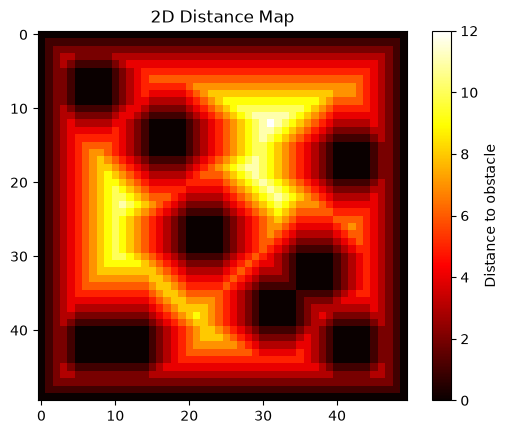

In [37]:
plt.imshow(map, cmap ='hot')
plt.colorbar(label='Distance to obstacle')
plt.title('2D Distance Map')
plt.show()

The distance map will help our particle filter evaluate how likely each possible robot position is, given our sensor observation. 

After resampling, particles that better explain the measurements are more likely to remain. This allows the filter to narrow down where the robot might be

## 2. Particle Initialization
Start with 1,000 particles distributed across the map.

In [38]:
particles = np.random.randint(50, size=(1000,2)) #Generates randoms integers, creating 1000 particles with 2 coordinates, and storing in one NumPy array

print(particles.shape)
print(particles[:5])

(1000, 2)
[[ 2 24]
 [ 0 41]
 [44 39]
 [35 14]
 [39 49]]


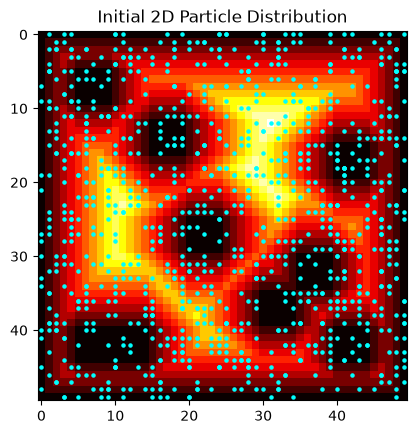

In [39]:
plt.imshow(map, cmap='hot')
plt.scatter(particles[:, 1], particles[:, 0], s=5, color='cyan') #Creating a scatter plot, where each dot represents 1 particle
plt.title('Initial 2D Particle Distribution')
plt.show()

## 3. 2D Motion Model
Move each particle in x and y and add Gaussian noise to represent motion uncertainty.

In [40]:
#Need to introduce Gaussian noise

def predict_move_2d(particles, action, sigma=1):
    N = len(particles) #Inputs: 1000 possible robot locations (particles), our action cmd, 
    #std.dev of Gaussian motion noise. For simplicity, assume independednt motion errors
    #with the same std.dev in both directions

    noise = np.random.normal(0, sigma, size=(N, 2)) #x and y

    new_particles = particles + action + noise

    new_particles = np.clip(new_particles, 0, 49)

    return new_particles

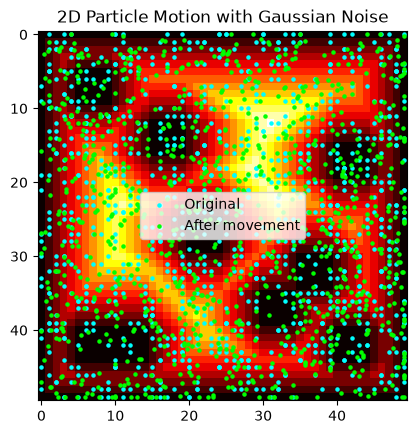

In [41]:
moved_particles = predict_move_2d(particles, action=np.array([1.0, 0.5]), sigma=1.0)

#Overlay both particle distributions on our distance map. Expect a high overlap because of the initial distribution variance
plt.imshow(map, cmap='hot')

plt.scatter(particles[:, 1], particles[:, 0],
            s=5, color='cyan', label='Original') #Original partciles

plt.scatter(moved_particles[:, 1], moved_particles[:, 0], #Predicted posterior position
            s=5, color='lime', label='After movement')

plt.legend()
plt.title('2D Particle Motion with Gaussian Noise')
plt.show()

## 4. Sensor and Likelihood Models
Use simulated range measurements and the distance map to score possible positions.

In [42]:
def distance_ray(x, theta, map, max_range=4, step=0.1):
    n, m = map.shape
    ray_theta = x[2] + theta
    ray = np.array([np.cos(ray_theta), np.sin(ray_theta)])
    for d in np.linspace(0,max_range, int(max_range // step)):
      point = x[:2] + d * ray
      cell = (round(point[0]), round(point[1]))
      if cell[0] < 0 or cell[0] >= n or cell[1] < 0 or cell[1] >= m: #Simulating one range measurement by tracing a ray until it encounters an obstacle or has reached maximum range
        return d - step
      if map[cell[0], cell[1]] == 0:
        return d
    return max_range

def scan_map(x, map, max_range = 4.0, theta_res=0.2):
    theta_range = np.arange(-np.pi,np.pi,theta_res)
    dists = []
    for theta in theta_range:
      dist = distance_ray(x, theta, map, max_range=max_range) #Generating multiple range measurements around the robot
      dists.append(dist)
    dists = np.array(dists)
    return dists, theta_range

def ray_prob(point: np.ndarray, map:np.ndarray, std = 0.5): #How likely a measured ray endpoint is, based on its distance from an obstacle
    i, j = round(point[0]), round(point[1])
    n, m = map.shape
    out_of_bounds_dist = 0
    # Handle rays that go out of bounds
    if i < 0:
      i = 0
      out_of_bounds_dist += abs(i-point[0])
    elif i >= n:
      i = n-1
      out_of_bounds_dist += abs(i-point[0])
    if j < 0:
      j = 0
      out_of_bounds_dist += abs(j-point[1])
    elif j >= m:
      j = m-1
      out_of_bounds_dist += abs(j-point[1])

    dist = map[i, j] + out_of_bounds_dist
    return np.exp(-dist**2/(2*std**2))/np.sqrt(2*np.pi*std**2)

def likelihood_field_range_finder(z_dists, z_thetas, x, map, z_max = 4.0, std=0.5): #Combining the individual ray likelihoods into an overall potential robot position
  q = 1
  eps = 0.02
  n, m = map.shape
  for z, theta in zip(z_dists, z_thetas):
    if z > z_max - eps:
      continue
    ray_theta = x[2] + theta
    ray = np.array([np.cos(ray_theta), np.sin(ray_theta)])
    point = x[:2] + z * ray
    q *= ray_prob(point, map, std=std)
  return q
#Ignoring yaw, we keep theta =0


[ 9.52702703  9.72972973 10.33783784 11.55405405 13.68243243 15.
 15.         15.         15.          6.68918919  6.08108108  6.89189189
  8.20945946 15.         15.         14.69594595 15.         15.
 15.         15.         15.         15.         15.         15.
 15.         15.         15.         15.         12.26351351 10.74324324
  9.93243243  9.62837838]


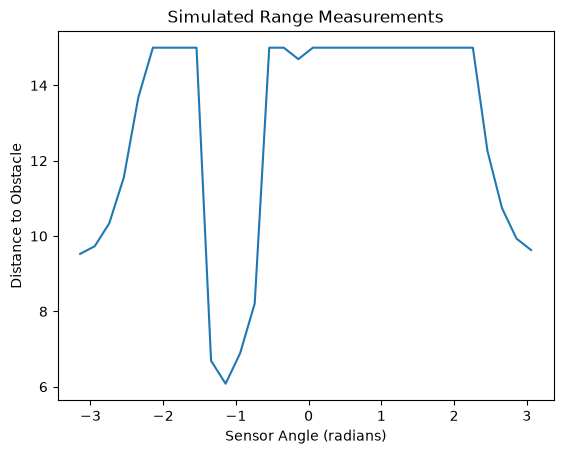

0.04237999106272858


In [43]:
robot = np.array([10, 25, 0])

z_dists, z_thetas = scan_map(robot, map, max_range=15)

print(z_dists)


plt.plot(z_thetas, z_dists)
plt.xlabel('Sensor Angle (radians)')
plt.ylabel('Distance to Obstacle')
plt.title('Simulated Range Measurements')
plt.show()

likelihood = likelihood_field_range_finder(
    z_dists, z_thetas, robot, map, z_max=15
)

print(likelihood)

In [44]:
position_A = np.array([10, 25, 0]) #Consider the simulated position that produded the observations
position_B = np.array([35, 10, 0]) # Different location

weight_A = likelihood_field_range_finder(
    z_dists, z_thetas, position_A, map, z_max=15 #Expecting pos.A to have a higher likelihood
)

weight_B = likelihood_field_range_finder(
    z_dists, z_thetas, position_B, map, z_max=15
)

print("Weight A:", weight_A)
print("Weight B:", weight_B)
print("Our likelihood model successfully gave pos. A ad higher likelihood than B. This is a measure of how well the observed sensor reading agrees with that candidate position")

Weight A: 0.04237999106272858
Weight B: 0.0
Our likelihood model successfully gave pos. A ad higher likelihood than B. This is a measure of how well the observed sensor reading agrees with that candidate position


## 5. Particle Weights
Calculate a likelihood for each predicted particle using the sensor measurements.

In [45]:
weights = []

for particle in moved_particles: #loop through ALL partciles in our predicted distribution
    position = np.array([particle[0], particle[1], 0]) #Calling theta =0 per professors comment to ignore yaw

    weight = likelihood_field_range_finder(
        z_dists, z_thetas, position, map, z_max=15
    )

    weights.append(weight)

weights = np.array(weights)

print("Number of weights:", len(weights))
print("Nonzero weights:", np.count_nonzero(weights))
print("Maximum weight:", np.max(weights))
print("Total weight:", np.sum(weights))

Number of weights: 1000
Nonzero weights: 610
Maximum weight: 0.0007762166124127188
Total weight: 0.0015543862365340563


## 6. Weight Normalization
Divide the likelihoods by their sum so the weights add up to 1.

In [46]:
def normalize_weights(weights):
    total = np.sum(weights)
    if total == 0:
        return np.ones(len(weights)) / len(weights)
    return weights / total

normalized_weights = normalize_weights(weights)
print('Sum of normalized weights:', normalized_weights.sum())

Sum of normalized weights: 1.0


## 7. Systematic Resampling
Select a new set of particles based on their normalized weights.

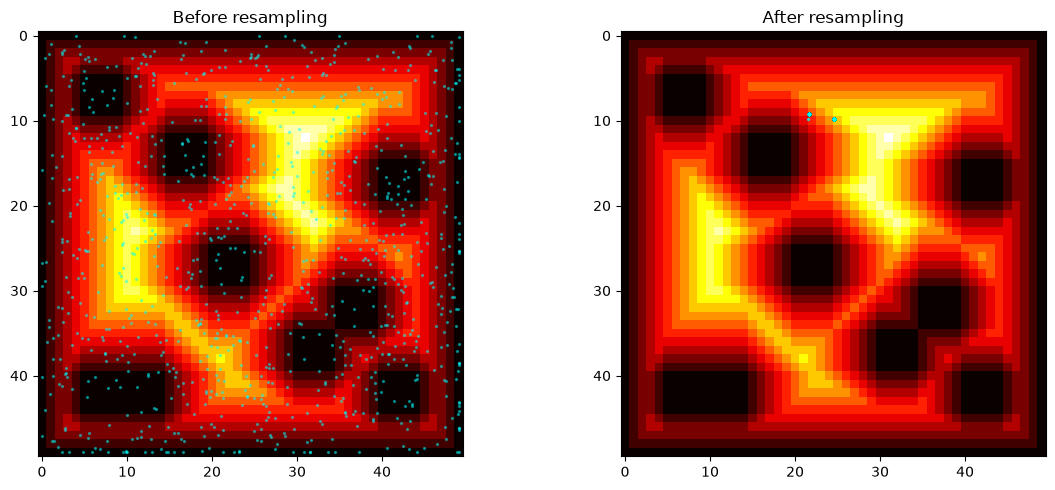

In [47]:
#resample

def systematic_resample(particles, weights):
    N = len(particles)
    positions = (np.random.random() + np.arange(N)) / N
    cumulative_sum = np.cumsum(weights)
    cumulative_sum[-1] = 1.0
    indexes = np.searchsorted(cumulative_sum, positions)
    return particles[indexes].copy()

resampled_particles = systematic_resample(moved_particles, normalized_weights)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cloud, title in zip(axes, [moved_particles, resampled_particles], ['Before resampling', 'After resampling']):
    ax.imshow(map, cmap='hot', origin='upper')
    ax.scatter(cloud[:, 1], cloud[:, 0], s=2, c='cyan', alpha=0.4)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 8. Multi-Step Particle Filter
Repeat motion prediction, sensor weighting, normalization, and resampling for 12 actions.

In [51]:
np.random.seed(7)
N = 1000
free_cells = np.argwhere(map > 0)
particles = free_cells[np.random.choice(len(free_cells), N)].astype(float)
true_robot = np.array([10, 25])
actions = [np.array([1, 0])] * 7 + [np.array([0, 1])] * 5
history = [particles.copy()]
true_history = [true_robot.copy()]
errors = []

for action in actions:
    # move the robot if the next cell is free
    next_pos = true_robot + action
    if 0 <= next_pos[0] < map.shape[0] and 0 <= next_pos[1] < map.shape[1] and map[tuple(next_pos)] > 0:
        true_robot = next_pos

    # add gaussian noise to simulate uncertainty
    particles = predict_move_2d(particles, action, sigma=0.7)

    z_dists, z_thetas = scan_map(np.array([*true_robot, 0]), map, max_range=15)
    weights = []
    for particle in particles:
        pose = np.array([particle[0], particle[1], 0])
        weights.append(likelihood_field_range_finder(z_dists, z_thetas, pose, map, z_max=15))

    weights = normalize_weights(np.array(weights))
    particles = systematic_resample(particles, weights)

    history.append(particles.copy())
    true_history.append(true_robot.copy())
    errors.append(np.linalg.norm(particles.mean(axis=0) - true_robot))

print('Completed', len(actions), 'filter updates')
print('Final true position:', true_robot)
print('Final particle mean:', particles.mean(axis=0))
print('Final position error:', round(errors[-1], 2), 'cells')

Completed 12 filter updates
Final true position: [17 30]
Final particle mean: [17.59698338 29.9785446 ]
Final position error: 0.6 cells


## 9. Results
The blue dots are particles, the red dot is the simulated robot, and the blue X is the particle mean. The second plot shows localization error after each update.

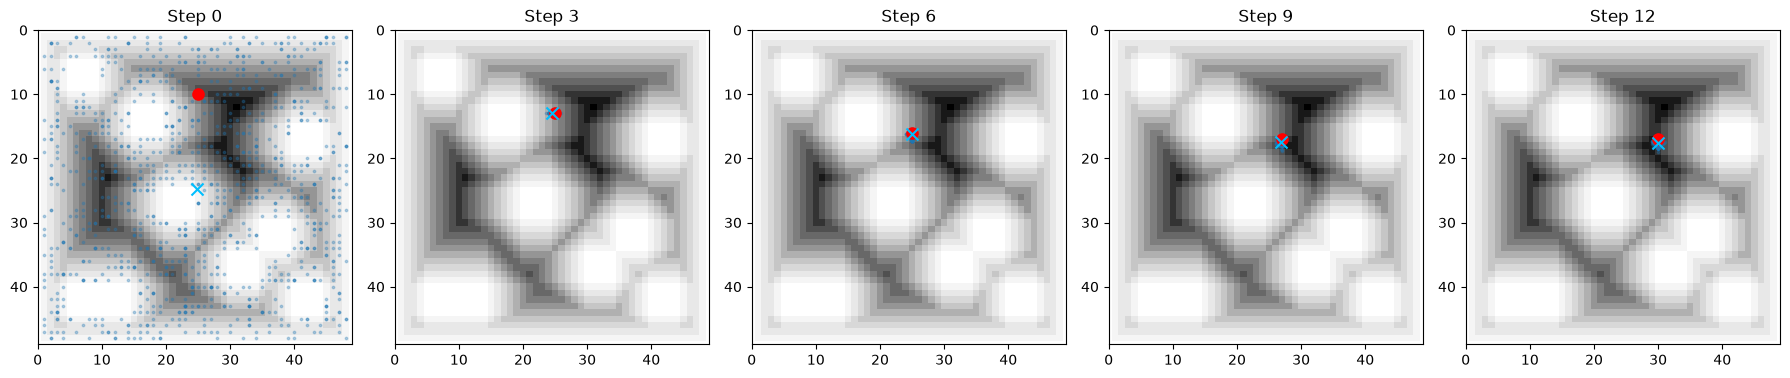

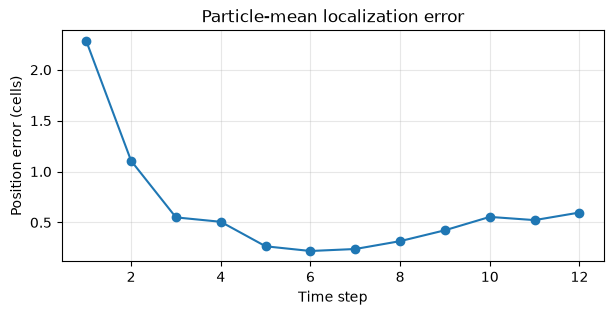

In [52]:
#Belief distributinos over time
steps= [0, 3, 6, 9, 12]
fig, axes = plt.subplots(1, len(steps), figsize=(18, 4))
for ax, t in zip(axes, steps):
    cloud = history[t]
    ax.imshow(map, cmap='Greys', origin='upper')
    ax.scatter(cloud[:, 1], cloud[:, 0], s=3, alpha=0.3, color='tab:blue')
    ax.scatter(true_history[t][1], true_history[t][0], color='red', marker='o', s=65)
    mean = cloud.mean(axis=0)
    ax.scatter(mean[1], mean[0], color='deepskyblue', marker='x', s=75)
    ax.set_title(f'Step {t}')
    ax.set_xlim(0, 49); ax.set_ylim(49, 0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3))
plt.plot(range(1, len(errors) + 1), errors, marker='o')
plt.xlabel('Time step'); plt.ylabel('Position error (cells)')
plt.title('Particle-mean localization error')
plt.grid(alpha=0.3)
plt.show()

## 10. Discussion

For this assignment, we extended the 1D particle filter to work in 2D by tracking the robot's position in both x and y. We used Gaussian noise to simulate uncertainty in the robot's movement, then we calculated and normalized the particle weights based on the sensor readings. After resampling, particles with higher weights were more likely to be selected. We repeated this process for 12 steps to see how the particle distribution changed over time.

From our plots, we can see that the particles started out spread across the map but gradually became more concentrated around the robot's actual position. The localization error dropped after the first few steps and stayed relatively low for the rest of the simulation.

One issue we ran into was the sensor range. Initially, we used a range of 4 cells, but most readings just returned 4 because the sensor wasn't detecting any obstacles. After increasing the range to 15 cells, we were able to detect obstacles at different distances.